# New Zealand IMF 2025 – Data Analysis with AI (LLM)

install libraires

In [1]:
!pip -q install pymupdf tiktoken transformers accelerate bitsandbytes sentence-transformers faiss-cpu

Upload & Extract the pdf

In [2]:
import os
import re
import json
import fitz
import tiktoken
from pathlib import Path
from google.colab import files

output_dir = Path("/content/nz_imf_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()
pdf_path = next((name for name in uploaded if name.lower().endswith(".pdf")), None)

if pdf_path is None:
    raise ValueError("Please upload the New Zealand IMF PDF.")

document = fitz.open(pdf_path)
pages = []

for page_number, page in enumerate(document, start=1):
    text = page.get_text("text", sort=True)

    text = re.sub(r"(?<=\w)-\s*\n(?=\w)", "", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)

    pages.append({
        "page": page_number,
        "text": text.strip()
    })

document.close()

full_text = "\n\n".join(
    page["text"] for page in pages if page["text"]
)

(output_dir / "cleaned_text.txt").write_text(full_text, encoding="utf-8")

with open(output_dir / "pages.json", "w", encoding="utf-8") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

print("PDF pages:", len(pages))
print("Extracted characters:", len(full_text))
print("Text extraction completed.")

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Saving 1934-7685-002.2025.issue-114-en.pdf to 1934-7685-002.2025.issue-114-en.pdf
PDF pages: 79
Extracted characters: 172449
Text extraction completed.


In [3]:
encoder = tiktoken.get_encoding("cl100k_base")

chunk_size = 450
overlap = 50
chunks = []

for page in pages:
    if not page["text"]:
        continue

    paragraphs = [
        p.strip()
        for p in re.split(r"\n\s*\n", page["text"])
        if p.strip()
    ]

    current_tokens = []

    for paragraph in paragraphs:
        paragraph_tokens = encoder.encode(paragraph + "\n\n")

        if len(current_tokens) + len(paragraph_tokens) > chunk_size:
            if current_tokens:
                chunks.append({
                    "chunk_id": len(chunks),
                    "page": page["page"],
                    "text": encoder.decode(current_tokens)
                })
                current_tokens = current_tokens[-overlap:]

        while len(paragraph_tokens) > chunk_size - len(current_tokens):
            space = chunk_size - len(current_tokens)

            if space <= 0:
                chunks.append({
                    "chunk_id": len(chunks),
                    "page": page["page"],
                    "text": encoder.decode(current_tokens)
                })
                current_tokens = current_tokens[-overlap:]
                space = chunk_size - len(current_tokens)

            current_tokens.extend(paragraph_tokens[:space])
            paragraph_tokens = paragraph_tokens[space:]

            chunks.append({
                "chunk_id": len(chunks),
                "page": page["page"],
                "text": encoder.decode(current_tokens)
            })

            current_tokens = current_tokens[-overlap:]

        current_tokens.extend(paragraph_tokens)

    if current_tokens:
        chunks.append({
            "chunk_id": len(chunks),
            "page": page["page"],
            "text": encoder.decode(current_tokens)
        })

with open(output_dir / "chunks.json", "w", encoding="utf-8") as f:
    json.dump(chunks, f, indent=2, ensure_ascii=False)

print("Total chunks:", len(chunks))
print("Pages covered:", len(set(c["page"] for c in chunks)))
print("Average chunk tokens:", round(
    sum(len(encoder.encode(c["text"])) for c in chunks) / len(chunks)
))

Total chunks: 140
Pages covered: 78
Average chunk tokens: 301


Load Qwen2.5-14B-Instruct

In [6]:

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

model_name = "Qwen/Qwen2.5-14B-Instruct"

if "model" not in globals():
    quant_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.bfloat16,
        bnb_4bit_use_double_quant=True
    )

    tokenizer = AutoTokenizer.from_pretrained(model_name)

    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        quantization_config=quant_config,
        device_map="auto",
        torch_dtype=torch.bfloat16
    )

model.eval()

def ask_llm(prompt, max_new_tokens=500):
    messages = [
        {
            "role": "system",
            "content": "You are a financial research assistant. Use only the supplied IMF evidence. Do not invent facts or numerical values."
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    response = outputs[0][inputs["input_ids"].shape[-1]:]

    return tokenizer.decode(
        response,
        skip_special_tokens=True
    ).strip()

print("Model:", model_name)
print("GPU:", torch.cuda.get_device_name(0))

Model: Qwen/Qwen2.5-14B-Instruct
GPU: NVIDIA A100-SXM4-80GB


In [7]:
test_prompt = """
Summarise New Zealand's economic outlook using the IMF evidence below.
Write no more than 70 words and do not introduce unsupported figures.

IMF evidence:
""" + pages[2]["text"][:4500]

response = ask_llm(test_prompt, max_new_tokens=150)

print("MODEL TEST RESPONSE")
print(response)

MODEL TEST RESPONSE
New Zealand's economic outlook forecasts gradual recovery with real GDP expanding 1.4% in 2025, accelerating to 2.7% in 2026, as inflation returns to target. Monetary policy easing will support consumption and investment, while fiscal policy aims to balance consolidation and growth. However, risks remain, including global uncertainty and potential natural disasters.


Identify IMF report sections

In [9]:
import re
import json

# Use the main IMF Staff Report only (PDF pages 9–26)
staff_text = " ".join(
    page["text"] for page in pages[8:26]
)

staff_text = re.sub(r"\s+", " ", staff_text)

section_patterns = [
    ("Reform and Innovation",
     r"A\. Reform and Innovation for Strong and Sustainable Growth"),

    ("Recent Developments",
     r"B\. Recent Developments: Bottoming Out and the End of Tight Monetary Policy"),

    ("Outlook and Risks",
     r"C\. Outlook and Risks: Recovery Amid Further Easing"),

    ("Fiscal Policy",
     r"A\. Fiscal Policy Is Appropriate and Should Continue Balancing Medium-Term Sustainability and Growth"),

    ("Monetary Policy",
     r"B\. The Case for a Period of Neutral Monetary Policy"),

    ("Housing and Financial Sector",
     r"C\. Housing and Financial Sector Reforms Are Key for Growth and Stability"),

    ("Productivity Reforms",
     r"D\. Reforms to Boost Productivity Are Needed"),

    ("Staff Appraisal",
     r"STAFF\s+A\s*(?:PP)?\s*RAISAL")
]

positions = []

for title, pattern in section_patterns:
    match = re.search(pattern, staff_text, re.IGNORECASE)

    if match is None:
        raise ValueError(f"Section not found: {title}")

    positions.append((match.start(), match.end(), title))

positions.sort()

sections = {}

for i, (start, end, title) in enumerate(positions):
    next_start = (
        positions[i + 1][0]
        if i + 1 < len(positions)
        else len(staff_text)
    )

    sections[title] = staff_text[end:next_start].strip()

with open(output_dir / "sections.json", "w", encoding="utf-8") as f:
    json.dump(sections, f, indent=2, ensure_ascii=False)

print("Sections detected:", len(sections))

for title, content in sections.items():
    print(title, "-", len(content), "characters")

print("Section extraction completed.")


Sections detected: 8
Reform and Innovation - 1366 characters
Recent Developments - 4568 characters
Outlook and Risks - 5094 characters
Fiscal Policy - 12355 characters
Monetary Policy - 6304 characters
Housing and Financial Sector - 9481 characters
Productivity Reforms - 5790 characters
Staff Appraisal - 4517 characters
Section extraction completed.


Generate eight section summaries and executive summary

In [10]:
import json
import re

def summarize_section(title, content):
    tokens = tokenizer.encode(content, add_special_tokens=False)

    if len(tokens) > 3000:
        notes = []

        for start in range(0, len(tokens), 2500):
            part = tokenizer.decode(tokens[start:start + 2500])

            prompt = f"""
Summarise the key economic evidence, risks and policy recommendations
from this IMF report extract in no more than 90 words.

Use only the supplied text. Do not invent figures.

Section: {title}

Text:
{part}
"""
            notes.append(ask_llm(prompt, max_new_tokens=180))

        source = "\n".join(notes)
    else:
        source = content

    prompt = f"""
You are summarising an IMF Staff Report section.

Section: {title}

Write a factual summary of 60–85 words.
Include important economic findings, numerical evidence where available,
and relevant risks or policy recommendations.

Use only the provided source. Do not add unsupported information.
Return only the summary.

Source:
{source}
"""

    summary = ask_llm(prompt, max_new_tokens=180)

    # Enforce the assignment's fewer-than-100-word requirement.
    words = summary.split()

    if len(words) >= 100:
        summary = ask_llm(
            f"Rewrite the following IMF summary in 70–85 words, "
            f"preserving its verified facts:\n{summary}",
            max_new_tokens=150
        )

    if len(summary.split()) >= 100:
        summary = " ".join(summary.split()[:99])

    return summary.strip()


section_summaries = {}

for title, content in sections.items():
    summary = summarize_section(title, content)
    section_summaries[title] = summary

    print(f"\n{title} ({len(summary.split())} words)")
    print(summary)

with open(output_dir / "section_summaries.json", "w", encoding="utf-8") as f:
    json.dump(section_summaries, f, indent=2, ensure_ascii=False)

executive_prompt = f"""
Prepare an executive summary of New Zealand's 2025 IMF Article IV report.

Use only the following section summaries.

Write 5–7 concise bullet points covering:
- Economic growth and recovery
- Inflation and monetary policy
- Fiscal policy and public debt
- Banking and financial stability
- Housing and structural challenges
- Main economic risks and policy priorities

Use factual language and avoid unsupported numerical claims.

Section summaries:
{json.dumps(section_summaries, ensure_ascii=False)}
"""

executive_summary = ask_llm(executive_prompt, max_new_tokens=450)

(output_dir / "executive_summary.txt").write_text(
    executive_summary, encoding="utf-8"
)

print("\nEXECUTIVE SUMMARY\n")
print(executive_summary)

print("\nSUMMARY VALIDATION")
print("Sections summarised:", len(section_summaries))
print("All summaries under 100 words:",
      all(len(s.split()) < 100 for s in section_summaries.values()))


Reform and Innovation (59 words)
The return of inflation to target is facilitating monetary policy easing, boosting consumption and investment, and supporting economic recovery through 2026. Fiscal policy aims to balance consolidation with growth. To sustain long-term growth, New Zealand must implement bold reforms to enhance productivity, competition, and innovation, address demographic challenges, and reform land use policies to tackle housing and infrastructure gaps.

Recent Developments (86 words)
In 2024, New Zealand's economy contracted by 0.5% as investment fell by 4.1%, private consumption stagnated, and public demand weakened. Tight financial conditions affected interest-rate-sensitive sectors like retail, construction, and manufacturing. Despite personal income tax cuts, real disposable income declined, constraining household spending. Unemployment rose to 5.1%, while net migration supported demand despite a record number of citizens leaving. Inflation reached the target ran

Seven financial stability themes

In [11]:
import re
import json
import pandas as pd

themes = {
    "Inflation & Prices": [
        r"\binflation\b", r"\bconsumer prices?\b",
        r"\bprice pressures?\b", r"\bdisinflation\b"
    ],
    "Interest Rates & Credit": [
        r"\binterest rates?\b", r"\bpolicy rates?\b",
        r"\bofficial cash rate\b", r"\bcredit growth\b",
        r"\blending\b"
    ],
    "Housing & Real Estate": [
        r"\bhousing\b", r"\bhouse prices?\b",
        r"\bmortgages?\b", r"\breal estate\b",
        r"\bproperty\b"
    ],
    "Banking Capital & Liquidity": [
        r"\bbanks?\b", r"\bbanking\b",
        r"\bcapital requirements?\b",
        r"\bliquidity\b", r"\bcapital buffers?\b"
    ],
    "Sovereign Debt": [
        r"\bpublic debt\b", r"\bgovernment debt\b",
        r"\bsovereign debt\b", r"\bfiscal deficits?\b",
        r"\bdebt sustainability\b"
    ],
    "Labor Market Dynamics": [
        r"\bunemployment\b", r"\bemployment\b",
        r"\blabor market\b", r"\blabour market\b",
        r"\bwages?\b", r"\bmigration\b"
    ],
    "Systemic Financial Risk": [
        r"\bfinancial stability\b", r"\bsystemic risks?\b",
        r"\bfinancial risks?\b", r"\bnon.performing loans?\b",
        r"\bmacroprudential\b", r"\bstress tests?\b"
    ]
}

# Scan the extracted Staff Report sections
analysis_text = " ".join(sections.values()).lower()

theme_counts = {}

for theme, patterns in themes.items():
    matches = []

    for pattern in patterns:
        matches.extend(re.finditer(pattern, analysis_text, re.IGNORECASE))

    # Avoid double-counting overlapping keyword matches.
    selected = []
    for match in sorted(matches, key=lambda m: (m.start(), -m.end())):
        if not selected or match.start() >= selected[-1][1]:
            selected.append((match.start(), match.end()))

    theme_counts[theme] = len(selected)

total = sum(theme_counts.values())

theme_df = pd.DataFrame({
    "theme": list(theme_counts.keys()),
    "count": list(theme_counts.values())
})

theme_df["percentage"] = (
    theme_df["count"] / total * 100
).round(2) if total else 0.0

theme_df = theme_df.sort_values(
    "count", ascending=False
).reset_index(drop=True)

with open(output_dir / "financial_themes.json", "w", encoding="utf-8") as f:
    json.dump(theme_df.to_dict(orient="records"), f, indent=2)

print("NEW ZEALAND FINANCIAL THEMES")
print(theme_df.to_string(index=False))
print("\nTotal keyword matches:", total)
print("Total percentage:", round(theme_df["percentage"].sum(), 2))

NEW ZEALAND FINANCIAL THEMES
                      theme  count  percentage
      Housing & Real Estate     34       22.52
Banking Capital & Liquidity     34       22.52
         Inflation & Prices     33       21.85
      Labor Market Dynamics     16       10.60
    Interest Rates & Credit     15        9.93
    Systemic Financial Risk     15        9.93
             Sovereign Debt      4        2.65

Total keyword matches: 151
Total percentage: 100.0


In [12]:
import json
import re

# Locate relevant IMF statistical tables automatically.
table_candidates = []

for page in pages:
    text = page["text"].lower()

    if page["page"] < 25:
        continue

    score = sum(
        term in text
        for term in [
            "financial soundness indicators",
            "nonperforming loans",
            "non-performing loans",
            "tier 1",
            "tier i capital",
            "regulatory capital"
        ]
    )

    if score >= 2:
        table_candidates.append((score, page))

table_candidates.sort(key=lambda x: x[0], reverse=True)

source_pages = [pages[4]]

# Add the latest banking statistics tables.
for score, page in table_candidates[:3]:
    if page["page"] not in [p["page"] for p in source_pages]:
        source_pages.append(page)

# Include monetary policy discussion.
source_pages.append(pages[9])

source_text = "\n\n".join(
    f"PDF PAGE {p['page']}\n{p['text'][:11000]}"
    for p in source_pages
)

print("Source pages:", [p["page"] for p in source_pages])

indicator_prompt = f"""
Extract economic indicators from the New Zealand 2025 IMF report.

Return ONLY a valid JSON object containing these seven fields:

country_name
gdp_growth_forecast_pct
headline_inflation_rate_pct
central_bank_policy_rate_pct
non_performing_loan_ratio
unemployment_rate_pct
tier_1_capital_ratio

Rules:
1. Use the IMF's 2025 projected annual real GDP growth.
2. Use projected 2025 annual average consumer price inflation.
3. Use the latest observed Official Cash Rate stated in the report,
   not the projected annual average.
4. Use the latest available non-performing loan ratio.
5. Use projected 2025 annual average unemployment.
6. Use the latest available Tier 1 capital ratio.
7. All numerical values must be percentages, not decimals.
8. Use null for any unavailable or uncertain value.
9. Do not calculate or invent missing indicators.
10. Return only JSON, without markdown or explanation.

IMF SOURCE:
{source_text}
"""

raw_response = ask_llm(indicator_prompt, max_new_tokens=650)

indicator_keys = [
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

financial_json = {
    "country_name": "New Zealand",
    **{key: None for key in indicator_keys}
}

try:
    match = re.search(r"\{.*\}", raw_response, re.DOTALL)
    if not match:
        raise ValueError("No JSON object found")

    extracted = json.loads(match.group())

    for key in indicator_keys:
        value = extracted.get(key)

        if isinstance(value, (int, float)) and not isinstance(value, bool):
            value = float(value)
            if 0 <= value <= 100:
                financial_json[key] = value

except (ValueError, TypeError, json.JSONDecodeError) as error:
    print("JSON extraction warning:", error)

with open(output_dir / "financial_indicators.json", "w", encoding="utf-8") as f:
    json.dump(financial_json, f, indent=2)

print("\nNEW ZEALAND FINANCIAL INDICATORS")
print(json.dumps(financial_json, indent=2))

print("\nMissing indicators:",
      sum(financial_json[k] is None for k in indicator_keys))

Source pages: [5, 10]

NEW ZEALAND FINANCIAL INDICATORS
{
  "country_name": "New Zealand",
  "gdp_growth_forecast_pct": 1.4,
  "headline_inflation_rate_pct": 2.4,
  "central_bank_policy_rate_pct": 3.6,
  "non_performing_loan_ratio": null,
  "unemployment_rate_pct": 5.3,
  "tier_1_capital_ratio": null
}

Missing indicators: 2


In [13]:
import json

# Preserve the original model extraction for evaluation.
original_indicators = financial_json.copy()

# Values checked directly against the IMF report tables.
source_audit = {
    "gdp_growth_forecast_pct": {
        "value": 1.4, "page": 5, "year": 2025
    },
    "headline_inflation_rate_pct": {
        "value": 2.4, "page": 5, "year": 2025
    },
    "central_bank_policy_rate_pct": {
        "value": 3.5, "page": 10, "year": 2025
    },
    "non_performing_loan_ratio": {
        "value": 0.7, "page": 39, "year": 2024
    },
    "unemployment_rate_pct": {
        "value": 5.3, "page": 5, "year": 2025
    },
    "tier_1_capital_ratio": {
        "value": 14.8, "page": 39, "year": 2024
    }
}

verified_indicators = {
    "country_name": "New Zealand"
}

audit_results = []

for field, source in source_audit.items():
    original = original_indicators.get(field)
    verified = source["value"]

    status = (
        "verified"
        if original == verified
        else "missing_corrected"
        if original is None
        else "value_corrected"
    )

    verified_indicators[field] = verified

    audit_results.append({
        "indicator": field,
        "original_value": original,
        "verified_value": verified,
        "source_page": source["page"],
        "reference_year": source["year"],
        "status": status
    })

financial_json = verified_indicators

with open(output_dir / "financial_indicators.json", "w") as f:
    json.dump(financial_json, f, indent=2)

with open(output_dir / "financial_source_audit.json", "w") as f:
    json.dump(audit_results, f, indent=2)

print("VERIFIED NEW ZEALAND FINANCIAL INDICATORS")
print(json.dumps(financial_json, indent=2))

print("\nSOURCE AUDIT")
for item in audit_results:
    print(
        item["indicator"],
        "|", item["status"],
        "| PDF page", item["source_page"]
    )

print("\nIndicators verified:", len(audit_results), "/ 6")
print("Missing values:",
      sum(v is None for k, v in financial_json.items()
          if k != "country_name"))

VERIFIED NEW ZEALAND FINANCIAL INDICATORS
{
  "country_name": "New Zealand",
  "gdp_growth_forecast_pct": 1.4,
  "headline_inflation_rate_pct": 2.4,
  "central_bank_policy_rate_pct": 3.5,
  "non_performing_loan_ratio": 0.7,
  "unemployment_rate_pct": 5.3,
  "tier_1_capital_ratio": 14.8
}

SOURCE AUDIT
gdp_growth_forecast_pct | verified | PDF page 5
headline_inflation_rate_pct | verified | PDF page 5
central_bank_policy_rate_pct | value_corrected | PDF page 10
non_performing_loan_ratio | missing_corrected | PDF page 39
unemployment_rate_pct | verified | PDF page 5
tier_1_capital_ratio | missing_corrected | PDF page 39

Indicators verified: 6 / 6
Missing values: 0


Extract economic strengths and vulnerabilities

In [14]:
import json
import re

# Select relevant IMF sections for qualitative analysis.
selected_sections = [
    "Reform and Innovation",
    "Recent Developments",
    "Outlook and Risks",
    "Fiscal Policy",
    "Housing and Financial Sector",
    "Productivity Reforms",
    "Staff Appraisal"
]

qualitative_source = "\n\n".join(
    f"{title}\n{sections[title]}"
    for title in selected_sections
)

qualitative_prompt = f"""
Analyse the following New Zealand 2025 IMF Staff Report.

Identify:
1. Exactly six macroeconomic strengths or growth drivers.
2. Exactly six economic vulnerabilities or challenges.

Requirements:
- Use only the supplied IMF evidence.
- Focus on meaningful economic and financial findings.
- Avoid repeating the same point.
- Each item must be a concise, factual sentence.
- Do not invent numerical values.
- Return only valid JSON.

Required format:
{{
  "strengths": [
    "Strength 1",
    "Strength 2",
    "Strength 3",
    "Strength 4",
    "Strength 5",
    "Strength 6"
  ],
  "vulnerabilities": [
    "Vulnerability 1",
    "Vulnerability 2",
    "Vulnerability 3",
    "Vulnerability 4",
    "Vulnerability 5",
    "Vulnerability 6"
  ]
}}

IMF SOURCE:
{qualitative_source}
"""

raw_qualitative = ask_llm(
    qualitative_prompt,
    max_new_tokens=900
)

def parse_qualitative(response):
    match = re.search(r"\{.*\}", response, re.DOTALL)

    if not match:
        raise ValueError("No JSON object returned")

    data = json.loads(match.group())

    for key in ["strengths", "vulnerabilities"]:
        items = data.get(key)

        if not isinstance(items, list) or len(items) != 6:
            raise ValueError(f"Invalid number of {key}")

        if not all(isinstance(item, str) and item.strip() for item in items):
            raise ValueError(f"Invalid entries in {key}")

    return data

try:
    qualitative_insights = parse_qualitative(raw_qualitative)

except (ValueError, json.JSONDecodeError):
    repair_prompt = f"""
Correct the following output into valid JSON with exactly
six strengths and six vulnerabilities.

Preserve only evidence-supported findings.
Do not invent new information.

Original output:
{raw_qualitative}

Source summaries:
{json.dumps(section_summaries, ensure_ascii=False)}
"""

    repaired = ask_llm(repair_prompt, max_new_tokens=900)
    qualitative_insights = parse_qualitative(repaired)

with open(output_dir / "qualitative_insights.json", "w", encoding="utf-8") as f:
    json.dump(qualitative_insights, f, indent=2, ensure_ascii=False)

print("NEW ZEALAND ECONOMIC STRENGTHS\n")

for i, item in enumerate(qualitative_insights["strengths"], 1):
    print(f"{i}. {item}")

print("\nNEW ZEALAND ECONOMIC VULNERABILITIES\n")

for i, item in enumerate(qualitative_insights["vulnerabilities"], 1):
    print(f"{i}. {item}")

print("\nVALIDATION")
print("Strengths:", len(qualitative_insights["strengths"]))
print("Vulnerabilities:", len(qualitative_insights["vulnerabilities"]))

NEW ZEALAND ECONOMIC STRENGTHS

1. Inflation returning to target allows for monetary policy easing, supporting consumption and investment.
2. The economic recovery is expected to continue with output gradually reaching potential.
3. Net migration helps support demand and addresses supply constraints.
4. Monetary policy easing is appropriate and timely, with interest rates held at a neutral level.
5. The current account deficit is expected to improve due to narrowing trade deficits and favorable terms of trade.
6. Financial stability risks are contained, with banks well-capitalized and profitable.

NEW ZEALAND ECONOMIC VULNERABILITIES

1. Weak domestic demand and a negative output gap pose risks to fiscal consolidation and balance sheets.
2. High household debt and mortgage arrears could exacerbate financial vulnerabilities.
3. Structural fiscal challenges from weak productivity growth and aging population strain long-term fiscal sustainability.
4. External risks from global economic sl

Extract economic strengths and vulnerabilities

In [16]:

import re
import json
import pandas as pd

# Table 1 is on PDF page 5.
table_text = pages[4]["text"]
years = list(range(2021, 2031))

trend_labels = {
    "GDP Growth (%)": r"Real GDP \(production\)",
    "Inflation (%)": r"Consumer prices \(avg, % change\)",
    "Unemployment (%)": r"Unemployment \(percent of labor force, ann\. average\)",
    "Official Cash Rate (%)": r"Official cash rate \(policy rate, percent, avg\)"
}

number_pattern = r"[-+]?\d+(?:\.\d+)?"
trend_data = {"Year": years}

for label, pattern in trend_labels.items():
    row = re.search(
        rf"(?m)^\s*{pattern}\s+((?:[-+]?\d+(?:\.\d+)?\s*)+)$",
        table_text,
        re.IGNORECASE
    )

    if row is None:
        raise ValueError(f"Could not locate table row: {label}")

    values = [
        float(x) for x in re.findall(number_pattern, row.group(1))
    ]

    if len(values) != len(years):
        raise ValueError(
            f"{label}: expected {len(years)} values, found {len(values)}"
        )

    trend_data[label] = values

trend_df = pd.DataFrame(trend_data)

# Convert wide data into long format for the dashboard.
trend_long = pd.melt(
    trend_df,
    id_vars=["Year"],
    var_name="Indicator",
    value_name="Value"
)

trend_long["Period"] = trend_long["Year"].apply(
    lambda year: "Historical / Estimate" if year <= 2024 else "IMF Projection"
)

trend_df.to_csv(output_dir / "economic_trends.csv", index=False)
trend_long.to_csv(output_dir / "economic_trends_long.csv", index=False)

with open(output_dir / "economic_trends.json", "w") as f:
    json.dump(trend_long.to_dict(orient="records"), f, indent=2)

print("NEW ZEALAND ECONOMIC TRENDS")
print(trend_df.to_string(index=False))

print("\nTREND VALIDATION")
print("Economic indicators:", len(trend_labels))
print("Years covered:", min(years), "-", max(years))
print("Total observations:", len(trend_long))
print("Missing values:", int(trend_long["Value"].isna().sum()))

NEW ZEALAND ECONOMIC TRENDS
 Year  GDP Growth (%)  Inflation (%)  Unemployment (%)  Official Cash Rate (%)
 2021             5.7            3.9               3.8                     0.3
 2022             2.9            7.2               3.3                     2.2
 2023             1.8            5.7               3.7                     5.2
 2024            -0.5            2.9               4.7                     4.7
 2025             1.4            2.4               5.3                     3.6
 2026             2.7            2.3               5.2                     3.3
 2027             2.7            2.2               4.7                     3.3
 2028             2.2            2.0               4.3                     3.3
 2029             2.2            2.0               4.5                     3.3
 2030             2.2            2.0               4.4                     3.3

TREND VALIDATION
Economic indicators: 4
Years covered: 2021 - 2030
Total observations: 40
Missing valu

Build FAISS vector index with local caching

In [17]:

import faiss
import numpy as np
import hashlib
import json
from sentence_transformers import SentenceTransformer

embedding_name = "sentence-transformers/all-mpnet-base-v2"

embedder = SentenceTransformer(
    embedding_name,
    device="cpu"
)

index_path = output_dir / "imf_faiss.index"
cache_path = output_dir / "embedding_cache.json"

chunk_texts = [c["text"] for c in chunks]

fingerprint = hashlib.sha256(
    json.dumps(
        {"model": embedding_name, "chunks": chunk_texts},
        ensure_ascii=False
    ).encode("utf-8")
).hexdigest()

cache_valid = False

if index_path.exists() and cache_path.exists():
    cache_info = json.loads(cache_path.read_text())
    cache_valid = cache_info.get("fingerprint") == fingerprint

if cache_valid:
    index = faiss.read_index(str(index_path))
    cache_valid = index.ntotal == len(chunks)

if cache_valid:
    print("Loaded cached FAISS index.")

else:
    embeddings = embedder.encode(
        chunk_texts,
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    index = faiss.IndexFlatIP(embeddings.shape[1])
    index.add(embeddings)

    faiss.write_index(index, str(index_path))

    cache_path.write_text(json.dumps({
        "model": embedding_name,
        "fingerprint": fingerprint,
        "chunk_count": len(chunks)
    }, indent=2))

    print("FAISS index created and cached.")

def retrieve_context(question, top_k=4):
    query_vector = embedder.encode(
        [question],
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype("float32")

    scores, indices = index.search(query_vector, top_k)

    results = []

    for score, idx in zip(scores[0], indices[0]):
        if idx < 0:
            continue

        results.append({
            "page": chunks[int(idx)]["page"],
            "chunk_id": int(idx),
            "score": round(float(score), 4),
            "text": chunks[int(idx)]["text"]
        })

    return results

print("\nRAG INDEX VALIDATION")
print("Embedding model:", embedding_name)
print("Indexed chunks:", index.ntotal)
print("Embedding dimensions:", index.d)
print("Index saved:", index_path.exists())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

FAISS index created and cached.

RAG INDEX VALIDATION
Embedding model: sentence-transformers/all-mpnet-base-v2
Indexed chunks: 140
Embedding dimensions: 768
Index saved: True


In [18]:

import json

rag_questions = [
    "What does the IMF recommend for New Zealand's monetary policy?",
    "What are the main financial stability risks facing New Zealand's banks and households?",
    "What fiscal policy measures does the IMF recommend to maintain debt sustainability?",
    "What structural reforms does the IMF recommend to improve housing supply and productivity?"
]

rag_results = []

for i, question in enumerate(rag_questions, 1):
    retrieved = retrieve_context(question, top_k=4)

    context = "\n\n".join(
        f"[PDF page {r['page']}, chunk {r['chunk_id']}]\n{r['text']}"
        for r in retrieved
    )

    prompt = f"""
Answer the question using ONLY the retrieved IMF evidence.

Rules:
- Write a factual answer of approximately 70–110 words.
- Cite the PDF page number for factual claims.
- Do not introduce unsupported numerical values.
- If evidence is insufficient, acknowledge the limitation.
- Do not use knowledge outside the retrieved context.

Question:
{question}

Retrieved IMF evidence:
{context}
"""

    answer = ask_llm(prompt, max_new_tokens=220)

    rag_results.append({
        "question": question,
        "answer": answer,
        "retrieved_pages": [r["page"] for r in retrieved],
        "retrieved_chunks": retrieved
    })

    print(f"\nQUESTION {i}")
    print(question)
    print("Retrieved pages:", [r["page"] for r in retrieved])
    print("\nANSWER:")
    print(answer)
    print("-" * 60)

with open(output_dir / "rag_audit.json", "w", encoding="utf-8") as f:
    json.dump(rag_results, f, indent=2, ensure_ascii=False)

print("\nRAG VALIDATION")
print("Questions answered:", len(rag_results))
print("All answers generated:", all(r["answer"] for r in rag_results))


QUESTION 1
What does the IMF recommend for New Zealand's monetary policy?
Retrieved pages: [3, 3, 75, 2]

ANSWER:
The IMF recommends that New Zealand's monetary policy move towards a less restrictive stance as inflation has returned to within the target band. The RBNZ has eased the Official Cash Rate (OCR) several times since August 2024, bringing it closer to the neutral rate. This easing is expected to provide a boost to consumption and investment, supporting economic growth. However, the outlook is subject to risks, including elevated global uncertainty and potential weaker-than-expected recovery due to a soft labor market or natural disasters. [Page 3, chunks 2 & 1]
------------------------------------------------------------

QUESTION 2
What are the main financial stability risks facing New Zealand's banks and households?
Retrieved pages: [50, 33, 45, 77]

ANSWER:
According to the IMF, New Zealand's banks face financial stability risks primarily from unexpected housing market cor

Load Mistral NeMo evaluator

In [19]:

import gc
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

# Free GPU memory before loading the evaluator.
if "model" in globals():
    del model
if "tokenizer" in globals():
    del tokenizer

gc.collect()
torch.cuda.empty_cache()

judge_name = "mistralai/Mistral-Nemo-Instruct-2407"

judge_tokenizer = AutoTokenizer.from_pretrained(judge_name)

judge_quant = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True
)

judge_model = AutoModelForCausalLM.from_pretrained(
    judge_name,
    quantization_config=judge_quant,
    device_map="auto",
    torch_dtype=torch.bfloat16
)

judge_model.eval()

def ask_judge(prompt, max_new_tokens=250):
    messages = [
        {
            "role": "system",
            "content": (
                "You are an independent IMF report evaluator. "
                "Compare claims against supplied evidence. "
                "Do not assume that generated answers are correct."
            )
        },
        {"role": "user", "content": prompt}
    ]

    inputs = judge_tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(judge_model.device)

    with torch.inference_mode():
        output = judge_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=judge_tokenizer.eos_token_id
        )

    return judge_tokenizer.decode(
        output[0][inputs["input_ids"].shape[-1]:],
        skip_special_tokens=True
    ).strip()

print("Evaluator LLM loaded successfully!")
print("Model:", judge_name)

config.json:   0%|          | 0.00/622 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/181k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.26M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

[transformers] The tokenizer you are loading from 'mistralai/Mistral-Nemo-Instruct-2407' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


model.safetensors.index.json:   0%|          | 0.00/29.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/363 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

Evaluator LLM loaded successfully!
Model: mistralai/Mistral-Nemo-Instruct-2407


Dashboard

In [20]:
import json
import re
from pathlib import Path

evaluation_path = output_dir / "llm_evaluations.json"

if evaluation_path.exists():
    evaluations = json.loads(evaluation_path.read_text())
else:
    evaluations = []

completed = {
    (e["category"], e["item"])
    for e in evaluations
}

def evaluate_output(category, item, source, answer):
    if (category, item) in completed:
        return

    prompt = f"""
Evaluate this IMF analysis output against its source evidence.

Category: {category}
Item: {item}

SOURCE EVIDENCE:
{source[:14000]}

OUTPUT TO EVALUATE:
{answer}

Score three dimensions from 1 (poor) to 5 (excellent):
- accuracy: Are factual claims supported by the evidence?
- completeness: Are important relevant findings included?
- consistency: Is the response internally coherent and consistent with the evidence?

Treat missing source evidence as a limitation.
Flag unsupported claims. Do not reward an answer simply because
it appears plausible. Return ONLY valid JSON:

{{
  "accuracy": 1,
  "completeness": 1,
  "consistency": 1,
  "reason": "Short critical explanation"
}}
"""

    raw = ask_judge(prompt, max_new_tokens=220)

    try:
        match = re.search(r"\{.*?\}", raw, re.DOTALL)
        result = json.loads(match.group()) if match else {}

        scores = {}
        for metric in ["accuracy", "completeness", "consistency"]:
            value = result.get(metric)
            if isinstance(value, (int, float)) and 1 <= value <= 5:
                scores[metric] = float(value)
            else:
                scores[metric] = None

        reason = str(result.get("reason", ""))

    except (ValueError, TypeError, json.JSONDecodeError):
        scores = {
            "accuracy": None,
            "completeness": None,
            "consistency": None
        }
        reason = "Evaluator response could not be parsed."

    evaluations.append({
        "category": category,
        "item": item,
        **scores,
        "reason": reason,
        "raw_response": raw
    })

    evaluation_path.write_text(
        json.dumps(evaluations, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

    completed.add((category, item))
    print(f"{category}: {item} - evaluated")


# 1. Section summaries
for title, summary in section_summaries.items():
    evaluate_output(
        "Summarisation",
        title,
        sections[title],
        summary
    )

# 2. Financial indicators
for field, audit in source_audit.items():
    page_text = pages[audit["page"] - 1]["text"]

    evidence = (
        page_text
        if field not in ["non_performing_loan_ratio", "tier_1_capital_ratio"]
        else "The relevant financial table requires visual source verification. "
             "Text evidence alone may be insufficient.\n" + page_text
    )

    evaluate_output(
        "Financial Extraction",
        field,
        evidence,
        json.dumps({
            "original_extraction": original_indicators.get(field),
            "verified_value": financial_json.get(field),
            "reference_year": audit["year"],
            "source_page": audit["page"]
        })
    )

# 3. RAG answers
for i, result in enumerate(rag_results, 1):
    evidence = "\n\n".join(
        f"PDF page {r['page']}:\n{r['text']}"
        for r in result["retrieved_chunks"]
    )

    evaluate_output(
        "RAG",
        f"Question {i}",
        evidence,
        result["answer"]
    )

print("\nEVALUATION SUMMARY")

import pandas as pd

evaluation_df = pd.DataFrame(evaluations)

print(
    evaluation_df.groupby("category")[
        ["accuracy", "completeness", "consistency"]
    ].mean().round(2).to_string()
)

print("\nTotal evaluations:", len(evaluation_df))
print("Expected evaluations: 18")
print("Unscored evaluations:",
      int(evaluation_df["accuracy"].isna().sum()))

Summarisation: Reform and Innovation - evaluated
Summarisation: Recent Developments - evaluated
Summarisation: Outlook and Risks - evaluated
Summarisation: Fiscal Policy - evaluated
Summarisation: Monetary Policy - evaluated
Summarisation: Housing and Financial Sector - evaluated
Summarisation: Productivity Reforms - evaluated
Summarisation: Staff Appraisal - evaluated
Financial Extraction: gdp_growth_forecast_pct - evaluated
Financial Extraction: headline_inflation_rate_pct - evaluated
Financial Extraction: central_bank_policy_rate_pct - evaluated
Financial Extraction: non_performing_loan_ratio - evaluated
Financial Extraction: unemployment_rate_pct - evaluated
Financial Extraction: tier_1_capital_ratio - evaluated
RAG: Question 1 - evaluated
RAG: Question 2 - evaluated
RAG: Question 3 - evaluated
RAG: Question 4 - evaluated

EVALUATION SUMMARY
                      accuracy  completeness  consistency
category                                                 
Financial Extraction      

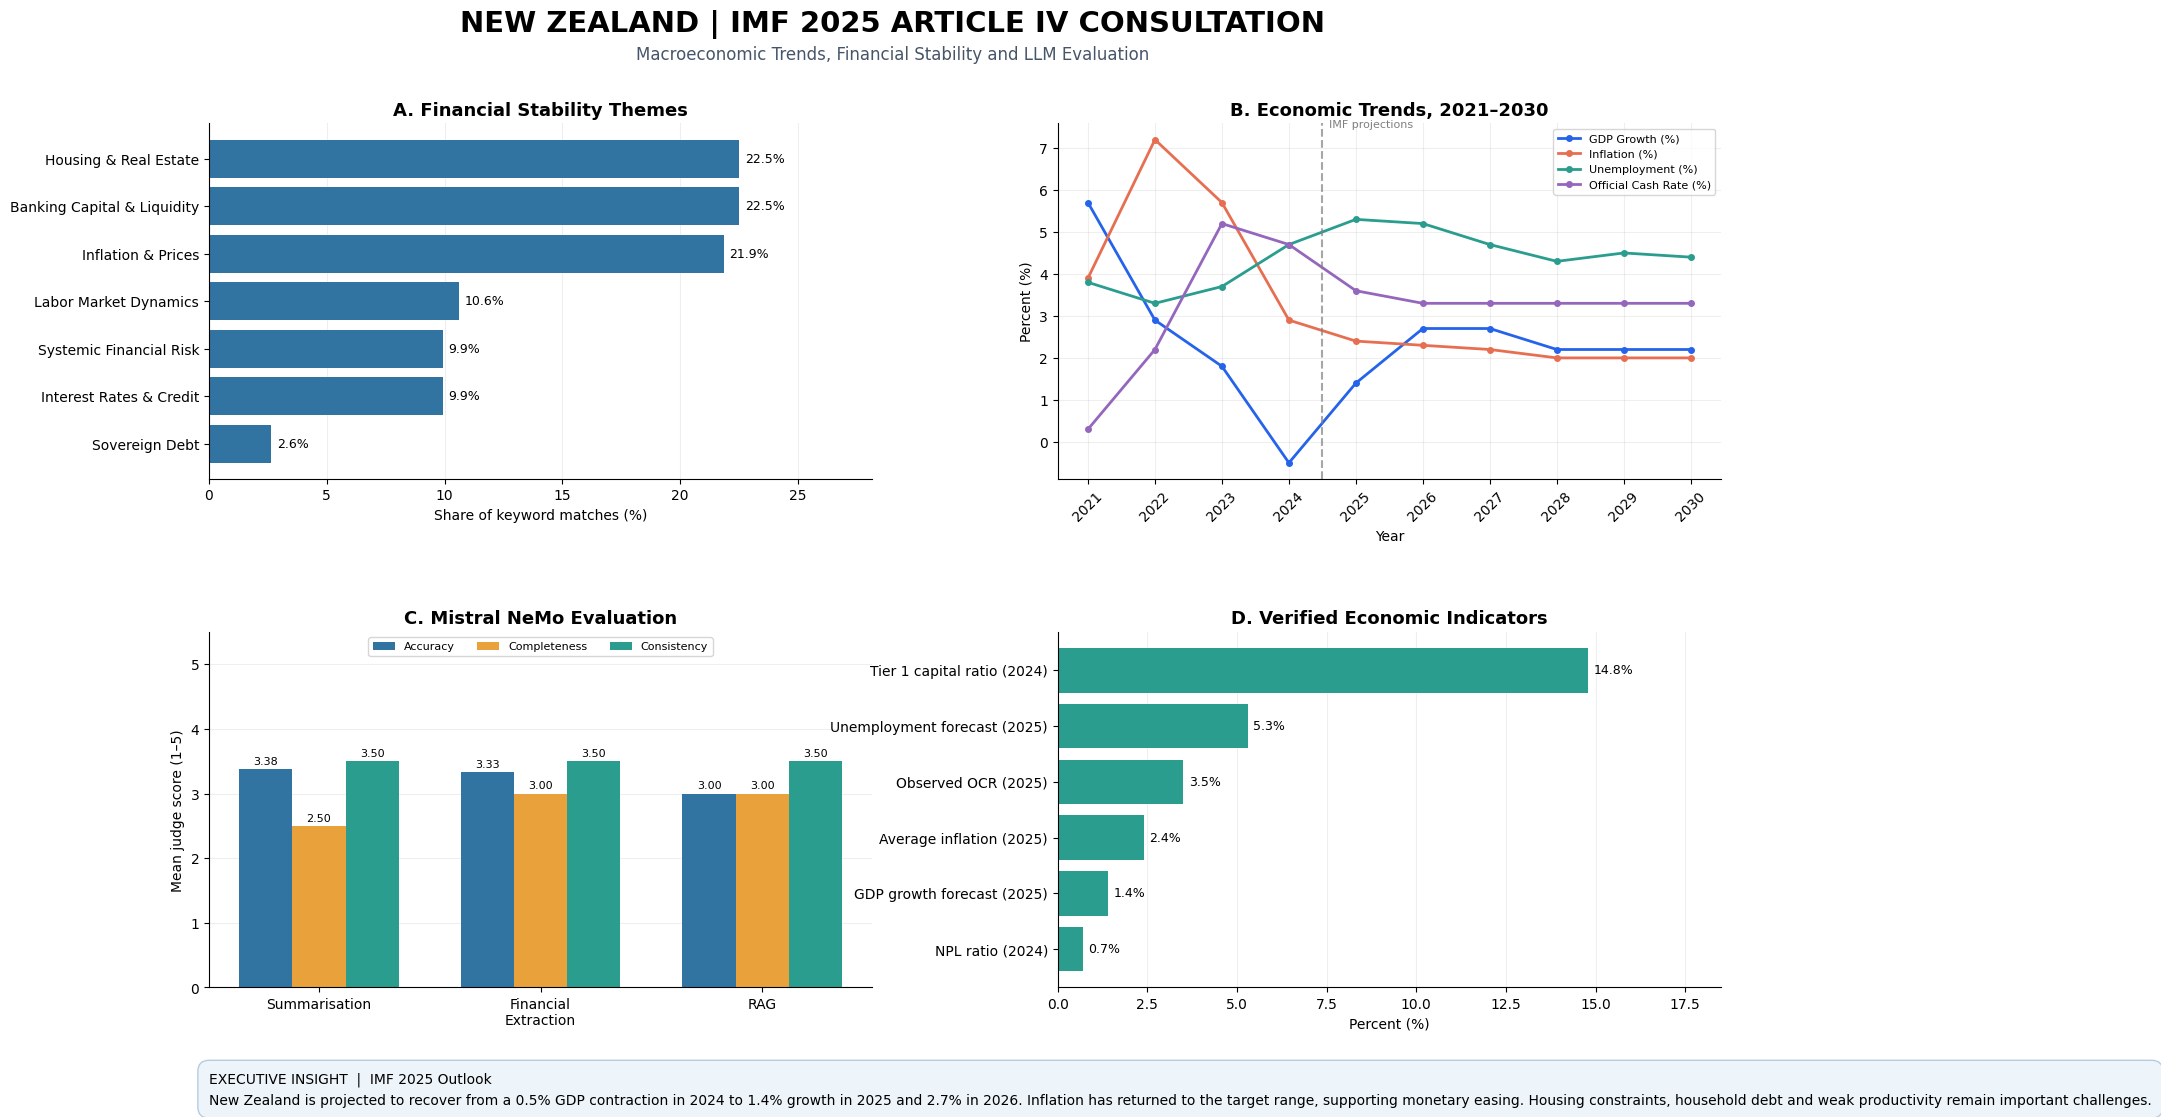

In [23]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load previously saved outputs.
themes_df = pd.read_json(output_dir / "financial_themes.json")
trends_df = pd.read_csv(output_dir / "economic_trends_long.csv")
eval_df = pd.read_json(output_dir / "llm_evaluations.json")

with open(output_dir / "financial_indicators.json") as f:
    indicators = json.load(f)

judge_df = (
    eval_df.groupby("category")[
        ["accuracy", "completeness", "consistency"]
    ].mean()
    .reindex(["Summarisation", "Financial Extraction", "RAG"])
)

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False
})

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.subplots_adjust(
    left=0.12, right=0.96, top=0.88,
    bottom=0.16, hspace=0.43, wspace=0.28
)

# Panel 1: Financial theme distribution
ax = axes[0, 0]
theme_plot = themes_df.sort_values("percentage")

bars = ax.barh(
    theme_plot["theme"],
    theme_plot["percentage"],
    color="#3274A1"
)

ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9)
ax.set_xlim(0, max(theme_plot["percentage"]) * 1.25)
ax.set_xlabel("Share of keyword matches (%)")
ax.set_title("A. Financial Stability Themes", fontweight="bold")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

# Panel 2: Economic trends
ax = axes[0, 1]

trend_colors = {
    "GDP Growth (%)": "#2563EB",
    "Inflation (%)": "#E76F51",
    "Unemployment (%)": "#2A9D8F",
    "Official Cash Rate (%)": "#9467BD"
}

for indicator, color in trend_colors.items():
    data = trends_df[
        trends_df["Indicator"] == indicator
    ].sort_values("Year")

    ax.plot(
        data["Year"], data["Value"],
        marker="o", markersize=4,
        linewidth=2, label=indicator, color=color
    )

ax.axvline(2024.5, color="gray", linestyle="--", alpha=0.7)
ax.text(
    2024.6, 7.5, "IMF projections",
    fontsize=8, color="gray"
)

ax.set_title("B. Economic Trends, 2021–2030", fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Percent (%)")
ax.set_xticks(range(2021, 2031))
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.2)
ax.legend(fontsize=8, loc="upper right")

# Panel 3: Independent evaluator comparison
ax = axes[1, 0]

metrics = ["accuracy", "completeness", "consistency"]
x = np.arange(len(judge_df))
width = 0.24

colors = ["#3274A1", "#E9A23B", "#2A9D8F"]

for i, metric in enumerate(metrics):
    values = judge_df[metric].values

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=metric.title(),
        color=colors[i]
    )

    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(
    ["Summarisation", "Financial\nExtraction", "RAG"]
)
ax.set_ylim(0, 5.5)
ax.set_ylabel("Mean judge score (1–5)")
ax.set_title("C. Mistral NeMo Evaluation", fontweight="bold")
ax.legend(ncol=3, fontsize=8, loc="upper center")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# Panel 4: Verified financial indicators
ax = axes[1, 1]

indicator_labels = {
    "gdp_growth_forecast_pct": "GDP growth forecast (2025)",
    "headline_inflation_rate_pct": "Average inflation (2025)",
    "central_bank_policy_rate_pct": "Observed OCR (2025)",
    "non_performing_loan_ratio": "NPL ratio (2024)",
    "unemployment_rate_pct": "Unemployment forecast (2025)",
    "tier_1_capital_ratio": "Tier 1 capital ratio (2024)"
}

indicator_plot = pd.DataFrame([
    {"Indicator": label, "Value": indicators.get(key)}
    for key, label in indicator_labels.items()
])

indicator_plot["Value"] = pd.to_numeric(
    indicator_plot["Value"], errors="coerce"
)

indicator_plot = indicator_plot.dropna().sort_values("Value")

bars = ax.barh(
    indicator_plot["Indicator"],
    indicator_plot["Value"],
    color="#2A9D8F"
)

ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9)
ax.set_xlim(0, max(indicator_plot["Value"]) * 1.25)
ax.set_xlabel("Percent (%)")
ax.set_title("D. Verified Economic Indicators", fontweight="bold")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

# Dashboard heading
fig.suptitle(
    "NEW ZEALAND | IMF 2025 ARTICLE IV CONSULTATION",
    fontsize=21, fontweight="bold", y=0.975
)

fig.text(
    0.5, 0.933,
    "Macroeconomic Trends, Financial Stability and LLM Evaluation",
    ha="center", fontsize=12, color="#475569"
)

# Executive insight overlay
executive_text = (
    "EXECUTIVE INSIGHT  |  IMF 2025 Outlook\n"
    "New Zealand is projected to recover from a 0.5% GDP contraction "
    "in 2024 to 1.4% growth in 2025 and 2.7% in 2026. "
    "Inflation has returned to the target range, supporting monetary easing. "
    "Housing constraints, household debt and weak productivity remain "
    "important challenges."
)

fig.text(
    0.12, 0.075,
    executive_text,
    ha="left", va="center",
    fontsize=10, linespacing=1.6,
    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="#EDF4FA",
        edgecolor="#B7CCE1"
    )
)


dashboard_path = output_dir / "new_zealand_imf_dashboard.png"

fig.savefig(
    dashboard_path,
    dpi=320,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)